In [1]:
import pandas as pd
import numpy as np

In [6]:
player_scores = pd.read_csv('player_model_scores.csv', index_col = 0)
proc_master_df = pd.read_csv('processed_master_df.csv', index_col = 0)

# Data Collection & (Minor) Cleaning
df = pd.merge(player_scores, proc_master_df, on = ['player', 'team']).drop(columns = ['total_ball_possession_events_per_match',
                                                                                      'defensive_effort_count',
                                                                                      'avg_pass_length'])

# Previewing the Data
df.head(6)

,player,team,mean_progressive_action_score,num_events,match_id,type,standardized_timestamp,start_x,start_y,end_x,end_y,delta_x,delta_y,distance_yards,is_progressive_pass,is_progressive_carry,is_progressive_dribble,is_progressive_action,most_frequent_pass_style,league_name
0,Thomas Meunier,Borussia Dortmund,0.666667,3,319097,Pass,72.13,23.0,72.8,64.4,71.5,41.4,-1.3,41.42,True,False,False,True,Right Foot,1. Bundesliga
1,Thomas Meunier,Borussia Dortmund,0.666667,3,319106,Pass,81.75,84.5,76.0,69.1,69.9,-15.4,-6.1,16.56,False,False,False,False,Right Foot,1. Bundesliga
2,Thomas Meunier,Borussia Dortmund,0.666667,3,319108,Pass,81.95,110.3,76.3,112.0,40.9,1.7,-35.4,35.44,True,False,False,True,Right Foot,1. Bundesliga
3,Thomas Meunier,Borussia Dortmund,0.666667,3,323406,Carry,81.68,91.3,74.8,84.5,76.0,-6.8,1.2,6.91,False,False,False,False,NaN,1. Bundesliga
4,Thomas Meunier,Borussia Dortmund,0.666667,3,323408,Carry,81.88,94.2,74.4,110.3,76.3,16.1,1.9,16.21,False,True,False,True,NaN,1. Bundesliga
5,Alex Oxlade-Chamberlain,Arsenal,0.527059,17,156073,Pass,47.04,68.8,72.9,81.5,75.0,12.7,2.1,12.87,True,False,False,True,Right Foot,Premier League


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69567 entries, 0 to 69566
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   player                         69567 non-null  object 
 1   team                           69567 non-null  object 
 2   mean_progressive_action_score  69567 non-null  float64
 3   num_events                     69567 non-null  int64  
 4   match_id                       69567 non-null  int64  
 5   type                           69567 non-null  object 
 6   standardized_timestamp         69567 non-null  float64
 7   start_x                        69567 non-null  float64
 8   start_y                        69567 non-null  float64
 9   end_x                          69567 non-null  float64
 10  end_y                          69567 non-null  float64
 11  delta_x                        69567 non-null  float64
 12  delta_y                        69567 non-null 



---

## Data Formatting, Standardization/Organization, and Cleaning

In [11]:
# Appropriate-izing NULL Values in the Dominant Foot/Body Part Column
df['most_frequent_pass_style'] = df['most_frequent_pass_style'].fillna('No Preferred Foot')

# Data Type Setting
df['match_id'] = df['match_id'].astype('object')

# Proper Sorting
df.sort_values(by = 'mean_progressive_action_score', ascending = False, inplace = True)

df.head(7)

,player,team,mean_progressive_action_score,num_events,match_id,type,standardized_timestamp,start_x,start_y,end_x,end_y,delta_x,delta_y,distance_yards,is_progressive_pass,is_progressive_carry,is_progressive_dribble,is_progressive_action,most_frequent_pass_style,league_name
2,Thomas Meunier,Borussia Dortmund,0.666667,3,319108,Pass,81.95,110.3,76.3,112.0,40.9,1.7,-35.4,35.44,True,False,False,True,Right Foot,1. Bundesliga
3,Thomas Meunier,Borussia Dortmund,0.666667,3,323406,Carry,81.68,91.3,74.8,84.5,76.0,-6.8,1.2,6.91,False,False,False,False,No Preferred Foot,1. Bundesliga
1,Thomas Meunier,Borussia Dortmund,0.666667,3,319106,Pass,81.75,84.5,76.0,69.1,69.9,-15.4,-6.1,16.56,False,False,False,False,Right Foot,1. Bundesliga
0,Thomas Meunier,Borussia Dortmund,0.666667,3,319097,Pass,72.13,23.0,72.8,64.4,71.5,41.4,-1.3,41.42,True,False,False,True,Right Foot,1. Bundesliga
4,Thomas Meunier,Borussia Dortmund,0.666667,3,323408,Carry,81.88,94.2,74.4,110.3,76.3,16.1,1.9,16.21,False,True,False,True,No Preferred Foot,1. Bundesliga
31,Alex Oxlade-Chamberlain,Arsenal,0.527059,17,269753,Carry,69.05,16.0,35.2,41.3,68.8,25.3,33.6,42.06,False,True,False,True,No Preferred Foot,Premier League
17,Alex Oxlade-Chamberlain,Arsenal,0.527059,17,156185,Pass,78.54,89.7,52.3,101.4,61.9,11.7,9.6,15.13,True,False,False,True,Left Foot,Premier League




---

## Data Visualization

---

### Univariate Analysis

In [25]:
# Selecting Categorical Columns
obj_cols = df.select_dtypes(include = 'object').drop(columns = ['match_id']).columns

# Selecting Numerical Columns
num_cols = df.select_dtypes(include = ['float', 'int64']).drop(columns = ['end_x', 'end_y', 'start_x', 'start_y'])

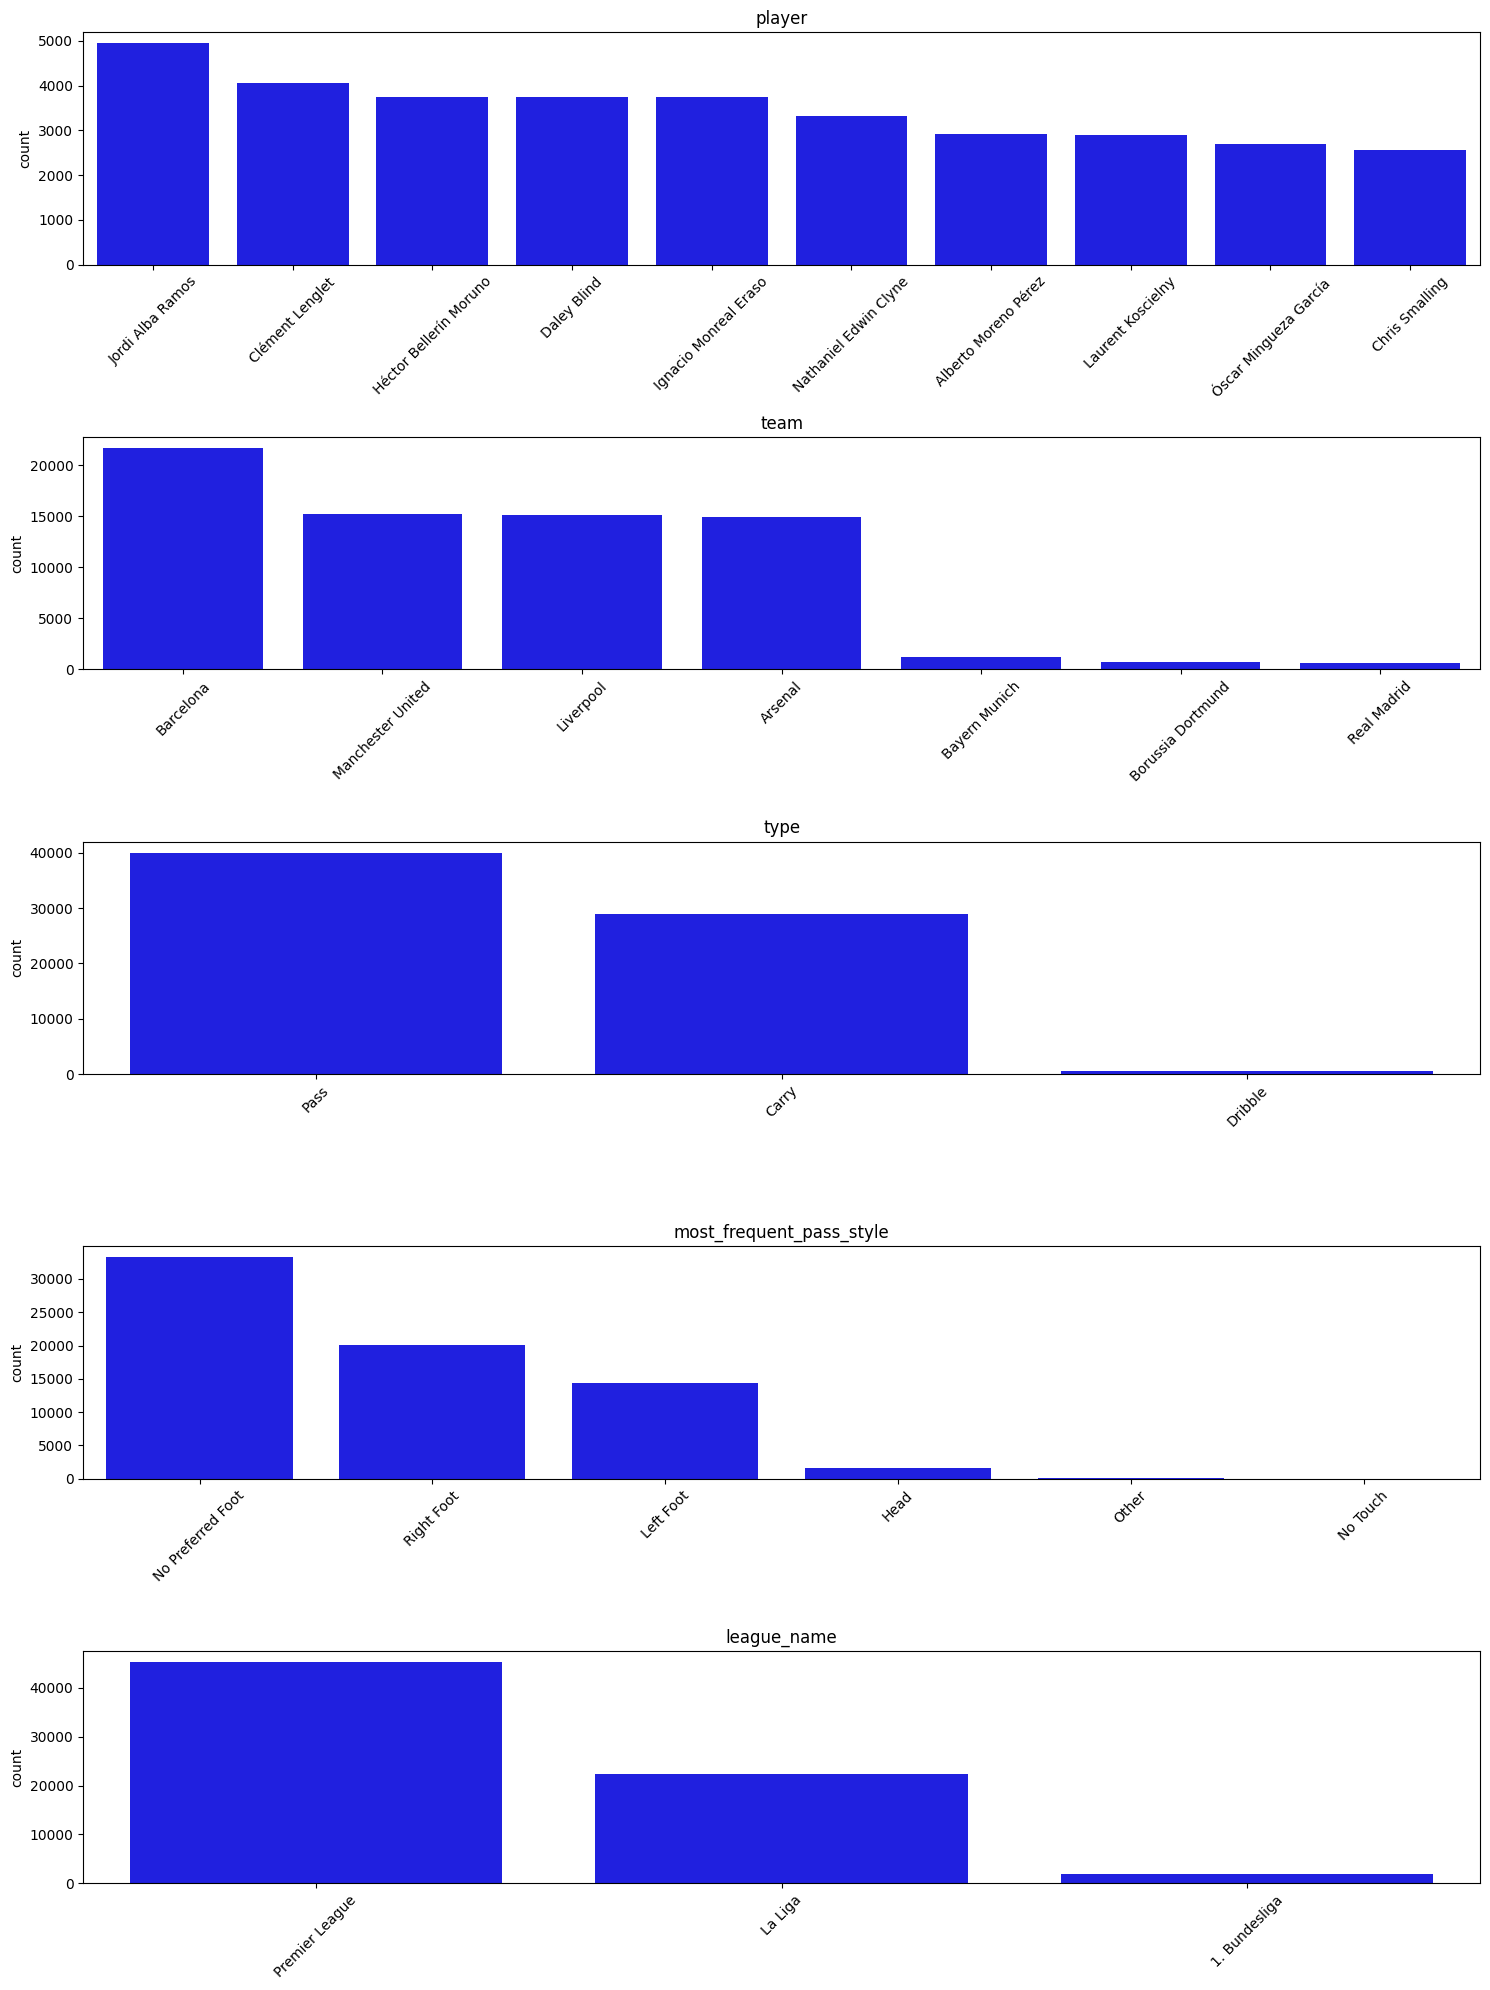

In [26]:
plt.figure(figsize = (15, 4 * len(obj_cols)))

for i, col in enumerate(obj_cols, 1):
  # Get the Top 10 Values per Column
  top10 = df[col].value_counts().nlargest(10)
  top10_index = top10.index

  ax = plt.subplot(len(obj_cols), 1, i)
  sns.countplot(x = df[col], order = top10_index, color = 'blue')
  plt.title(f"{col}")
  plt.xticks(rotation = 45)

  ax.set_xlabel('')

plt.tight_layout()
plt.show()

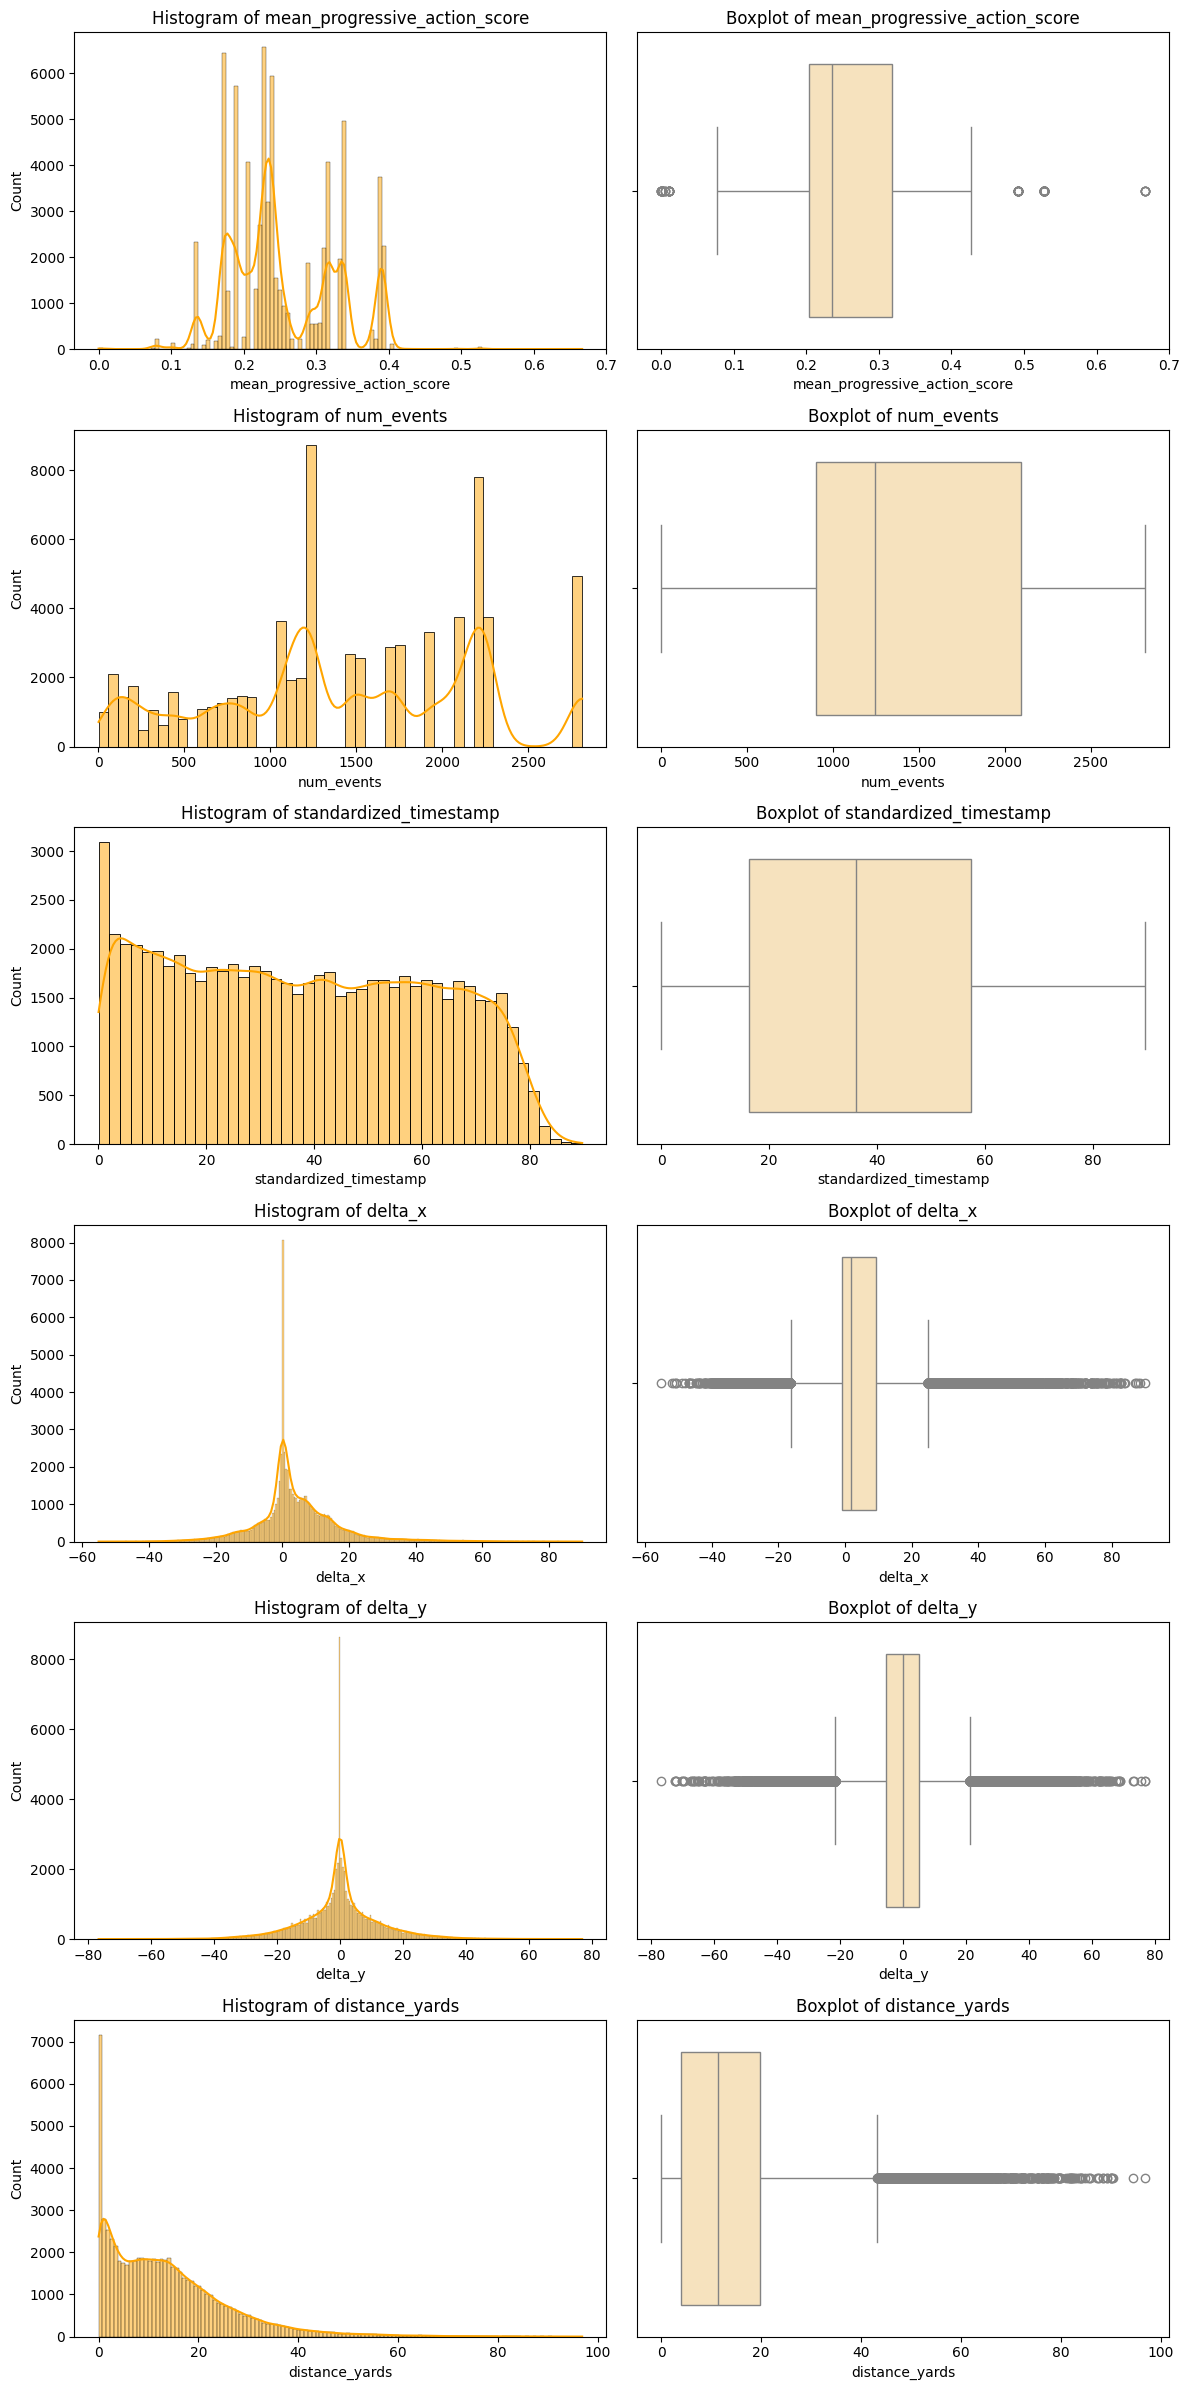

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Preparing Numerical Columns for Analytical Visuals
n_cols = len(num_cols.columns)

# Dynamically adjusting the figure size and grid rows based on the number of columns
plt.figure(figsize = (12, 4 * n_cols))

# Looping through each Numerical Column and Plotting, respectively, Histograms and Boxplots
for i, col in enumerate(num_cols.columns):
  # Histogram
  ax1 = plt.subplot(n_cols, 2, 2*i + 1)
  sns.histplot(df[col], kde = True, color = 'orange')
  plt.title(f"Histogram of {col}")

  # Boxplot
  ax2 = plt.subplot(n_cols, 2, 2*i + 2)
  sns.boxplot(x = df[col], color = 'moccasin')
  plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()



---

### Bivariate Analysis

In [54]:
def scorebar_analysis(df, numerical_col, categorical_col = 'player', categorical_title = 'players', top_n = 20):
  # Sort the dataframe to get the top players
  df_sorted = df.sort_values(by = numerical_col, ascending = False).head(top_n)

  plt.figure(figsize = (12, 8))
  sns.set(style = "whitegrid")

  # Horizontal Barplot
  sns.barplot(
      x = numerical_col,
      y = categorical_col,
      data = df_sorted,
      palette = 'viridis',
      hue = categorical_col,
      legend = False
  )

  plt.title(f"Top {top_n} {categorical_title.title()} by {numerical_col.replace('_', ' ').title()}")
  plt.xlabel(numerical_col.replace('_', ' ').title())
  plt.ylabel(categorical_col.title())
  plt.tight_layout()
  plt.show()

In [55]:
player_scores = df.groupby('player')['mean_progressive_action_score'].mean().round(2)
player_scores.sort_values(ascending = False, inplace = True)
player_scores_df = player_scores.reset_index()

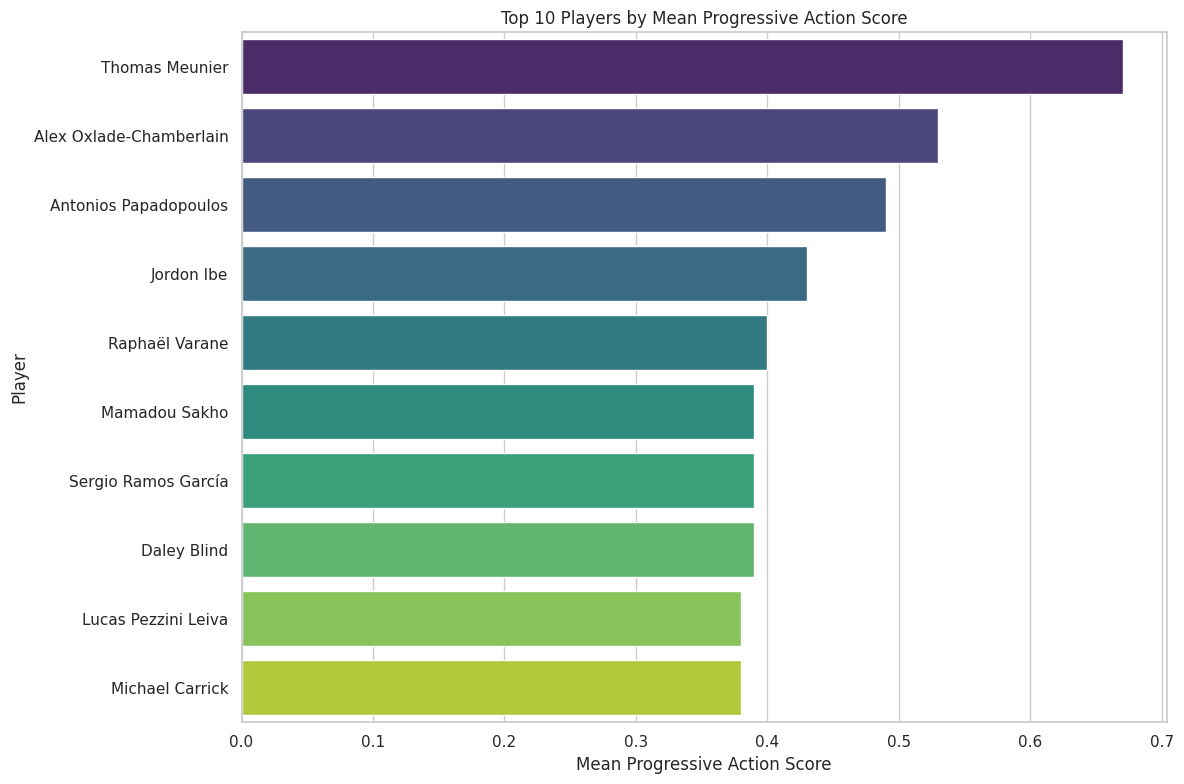

In [56]:
# We pass the dataframe, the score column, and optionally the category column
scorebar_analysis(player_scores_df, 'mean_progressive_action_score', categorical_col = 'player', categorical_title = 'players', top_n = 10)

In [59]:
team_pass_lengths = df.groupby('team')['distance_yards'].mean().round(2)
team_pass_lengths.sort_values(ascending = False, inplace = True)
team_pass_lengths_df = team_pass_lengths.reset_index().rename(columns = {'distance_yards': 'avg_pass_yards'})

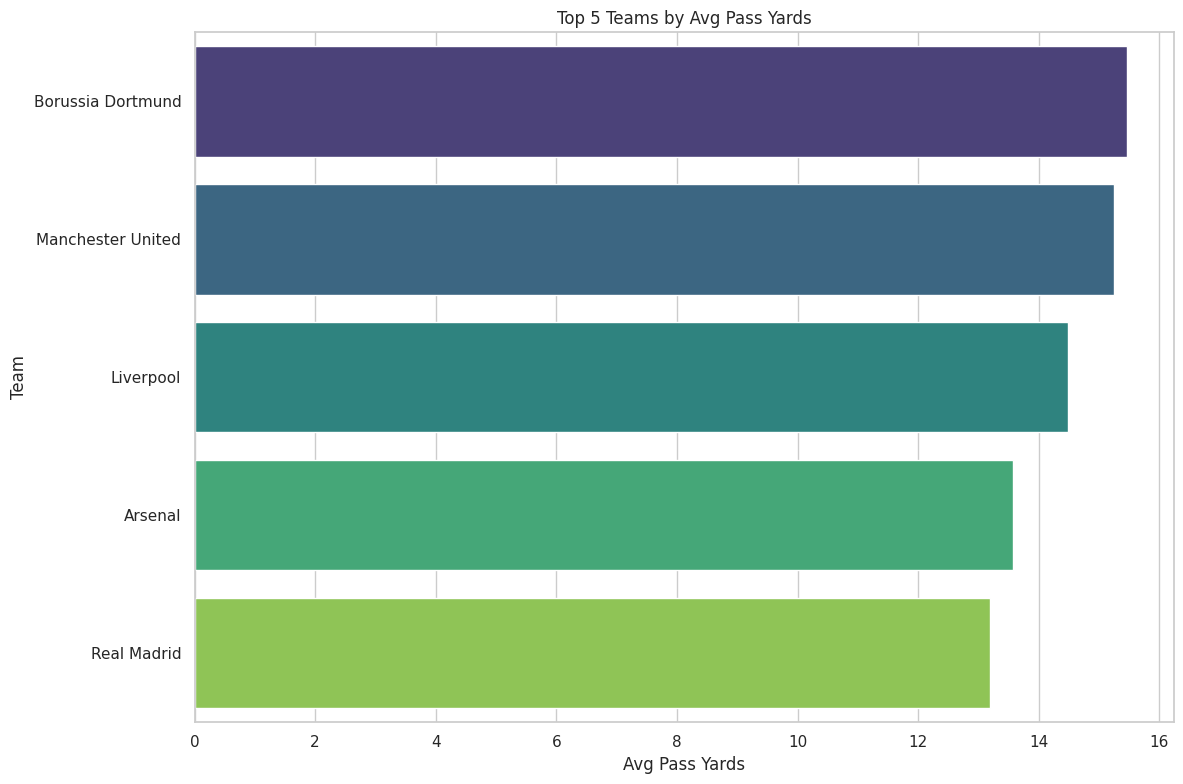

In [61]:
scorebar_analysis(team_pass_lengths_df, 'avg_pass_yards', categorical_col = 'team', categorical_title = 'teams', top_n = 5)



---

### Finally, Before we Move on to the Core PCA + Clustering for *Player Archetypes*

---

## Analyzing the Confidence Interval (CI)

* Calculate the Mean and Standard Deviation of the Key Value: Mean Progressive Action Score
* Calculate the Standard Error
* Calculate the Confidence Interval

In [ ]:
# To achieve this, we need to have Normal Distribution of the Data
# Will go with the Central Limit Theorem to Transform Data to a Normal Distribution

In [77]:
from scipy.stats import norm

def plot_sample_means(arr_df, confidence_interval, label_arr, color):
    no_of_agents = 2000
    fig, axes = plt.subplots(2, 2, figsize = (15, 15))
    fig.suptitle(f"{confidence_interval*100}% Confidence Interval", fontsize = 16)
    subplot_no = 1

    ci_data = []

    # Using 4 sample sizes to fit the 2x2 grid layout
    for n in [10, 100, 1000, 2000]:
        new_sample = []
        sample_mean = []
        for data in arr_df:
            new_sample.append(np.random.choice(a = data, size = (no_of_agents, n))) # (rows, columns)
            sample_mean.append(new_sample[-1].mean(axis = 1))

        plt.subplot(2, 2, subplot_no)
        plt.title(f"{no_of_agents} sample means; sample size (n) = {n}")

        for i in range(len(sample_mean)):
            sns.histplot(x = sample_mean[i], stat = "probability", kde = True, label = f"{label_arr[i]} Sample", color = color[i])

        # Calculate CIs
        ci_arr = []
        for i in range(len(sample_mean)):
            ci = norm.interval(confidence_interval, loc = sample_mean[i].mean(), scale = sample_mean[i].std())
            ci_arr.append(ci)
            ci_data.append({
                'Confidence Interval': int(confidence_interval * 100),
                'Sample': label_arr[i],
                'Sample Size': n,
                'Lower Limit': ci[0],
                'Upper Limit': ci[1]
            })

        # Adding Vertical lines for CIs
        for i in range(len(sample_mean)):
            plt.axvline(ci_arr[i][0], color = color[i], linestyle = '--', label = f"{label_arr[i]} {confidence_interval*100:.0f}% CI" if subplot_no == 1 else "")
            plt.axvline(ci_arr[i][1], color = color[i], linestyle = '--')

        plt.xlabel(f"n = {n}; " + "; ".join([f"{label_arr[i]}_m = {sample_mean[i].mean():.1f}; {label_arr[i]}_se = {sample_mean[i].std():.2f}" for i in range(len(sample_mean))]))
        plt.legend()
        subplot_no += 1

    plt.tight_layout()
    plt.show()
    return pd.DataFrame(ci_data)

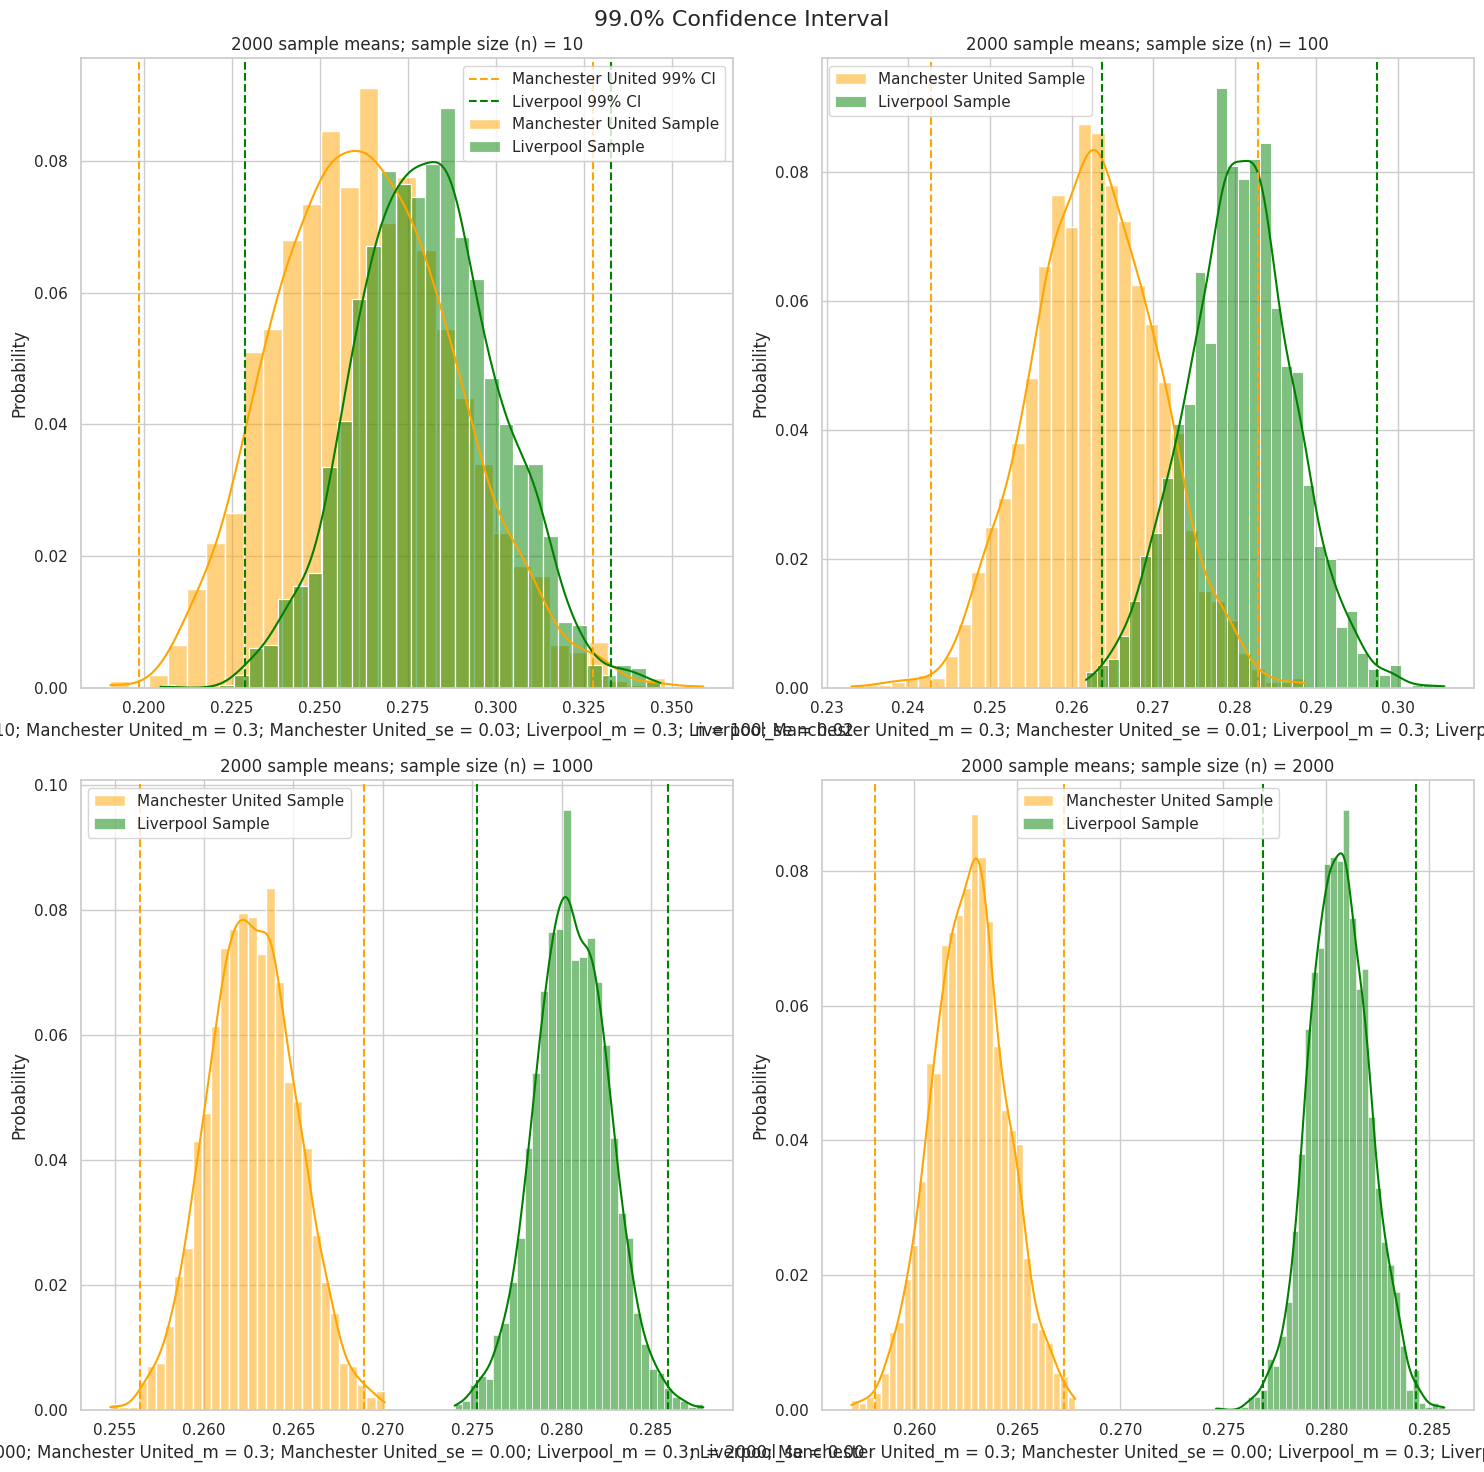

In [79]:
# Choosing my Fav Team (Manchester United! ^_^) and our arch-rivals-for-life: Liverpool!
arr_df = [
    df.loc[df['team'].str.contains('Manchester United'), 'mean_progressive_action_score'],
    df.loc[df['team'].str.contains('Liverpool'), 'mean_progressive_action_score']
]

label_arr = ['Manchester United', 'Liverpool']
color = ['orange', 'green']

# Let's Go - with a 99% CI!
confidence_interval = 0.99
ci99 = plot_sample_means(arr_df, confidence_interval, label_arr, color)

In [85]:
# Calculate Percentage Change and mask values where the Sample Group remains the same
ci99['prog_value_lowerlimit_diff%'] = ci99['Lower Limit'].pct_change(periods = 1).where(ci99['Sample'] != ci99['Sample'].shift(1))
ci99['prog_value_upperlimit_diff%'] = ci99['Upper Limit'].pct_change(periods = 1).where(ci99['Sample'] != ci99['Sample'].shift(1))

ci99

,Confidence Interval,Sample,Sample Size,Lower Limit,Upper Limit,prog_value_lowerlimit_diff,prog_value_upperlimit_diff,prog_value_lowerlimit_diff%,prog_value_upperlimit_diff%
0,99,Manchester United,10,0.198690,0.327542,NaN,NaN,NaN,NaN
1,99,Liverpool,10,0.228562,0.332574,0.150347,0.015360,0.150347,0.015360
2,99,Manchester United,100,0.242783,0.282906,0.062218,-0.149344,0.062218,-0.149344
3,99,Liverpool,100,0.263742,0.297492,0.086328,0.051557,0.086328,0.051557
4,99,Manchester United,1000,0.256422,0.268969,-0.027752,-0.095876,-0.027752,-0.095876
5,99,Liverpool,1000,0.275264,0.285920,0.073478,0.063021,0.073478,0.063021
6,99,Manchester United,2000,0.258079,0.267258,-0.062429,-0.065273,-0.062429,-0.065273
7,99,Liverpool,2000,0.276900,0.284366,0.072924,0.064014,0.072924,0.064014


Insights:

* Using CLT, we can infer that the CI for the Progressive Action Value is narrowed down and, thus, was Precise when the Sample Size was increased. Helps the Business make better decisions.
* For the 99% CI and its Sample Sizes of 1000 and 2000, we can confirm that the Confidence Interval is not Overlapping and that there is a **clear distinction** between the Average Progressive Action value of Man Utd and Liverpool players - Liverpool players are *better* (higher-value) and more consistently better (narrower spread) passers than Man Utd players, according to this latest data wave.
However, the distinction is not by a lot.

In [88]:
df.sample(5)

,player,team,mean_progressive_action_score,num_events,match_id,type,standardized_timestamp,start_x,start_y,end_x,end_y,delta_x,delta_y,distance_yards,is_progressive_pass,is_progressive_carry,is_progressive_dribble,is_progressive_action,most_frequent_pass_style,league_name
695,Mamadou Sakho,Liverpool,0.391801,1244,118758,Pass,45.73,61.4,24.2,81.9,2.4,20.5,-21.8,29.92,True,False,False,True,Left Foot,Premier League
8358,Per Mertesacker,Arsenal,0.339523,1238,239540,Carry,61.77,50.2,73.7,56.9,58.9,6.7,-14.8,16.25,False,False,False,False,No Preferred Foot,Premier League
31466,Ignacio Monreal Eraso,Arsenal,0.239301,2259,109287,Pass,28.25,34.3,5.8,36.1,15.9,1.8,10.1,10.26,False,False,False,False,Left Foot,Premier League
25527,Marius Wolf,Borussia Dortmund,0.256829,82,319021,Pass,37.63,86.8,68.6,94.9,51.6,8.1,-17.0,18.83,False,False,False,False,Right Foot,1. Bundesliga
49602,Matteo Darmian,Manchester United,0.206102,1157,148798,Pass,23.30,66.0,68.8,90.8,73.9,24.8,5.1,25.32,True,False,False,True,Head,Premier League


In [112]:
import plotly.express as px

# 1. Aggregate the data
aggregated_series = df[df['team'] == 'Manchester United'].agg({
    "num_events": "mean",
    "mean_progressive_action_score": "mean",
    "standardized_timestamp": "mean",
    "distance_yards": "mean"
})

# 2. Convert the Series to a DataFrame and reset the index to get clean columns
data = aggregated_series.reset_index()
data.columns = ['Metric', 'Value']

# from sklearn.preprocessing import StandardScaler
# data['Value'] = StandardScaler().fit_transform(data[['Value']])

data['Value'] = np.log(data['Value'])

# 3. Create the polar plot using the corrected DataFrame columns
fig = px.line_polar(
    data,
    r = 'Value',
    theta = 'Metric',
    line_close = True,
    title = 'Manchester United Team Actions',
    render_mode = 'svg'
)

fig.update_traces(fill = 'toself')
fig.show()

In [103]:
data

,Metric,Value
0,mean_progressive_action_score,-1.137256
1,standardized_timestamp,1.296630
2,distance_yards,-0.159374
